In [5]:
# imports
import csv
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np

# Figure 12(a)

In [6]:
# Base plotting code
SHOW_LEGEND = False
INCLUDE_SVM = False
LEGEND_LOC = "lower center"
LEGEND_BBOX_TO_ANCHOR = (0.5, 0.0)
FIGURE_SIZE = (10, 4)
DATASETS = ("cicids17", "ciciot22")
# MODELS = ("lr", "slp", "nb", "km", "svm")
MODELS = ("km", "lr", "nb", "slp", "svm")
VERSIONS = ("original_float", "reformulated_float", "original_fixed", "reformulated_fixed")
LABELS = ("V1", "V2", "V3", "V4")
HATCHES = ("///", "\\\\", "xxx", "...")
COLORS = tuple(tuple(0.6 * channel + 0.4 for channel in to_rgb(color))
               for color in ("tab:blue", "tab:orange", "tab:green", "tab:red"))
DATA_PATH = Path("data/approximation_results.csv")


def plot_approx_error(dataset):
    if dataset not in DATASETS:
        raise ValueError(f"DATASET must be one of {DATASETS}, got {dataset!r}")
    with DATA_PATH.open(newline="", encoding="utf-8") as results:
        rows = [row for row in csv.DictReader(results) if row["dataset"] == dataset]
    values = {}
    for row in rows:
        model = row["model"].split("_")[0]
        version = "original_fixed" if row["variant"] == "ss_fixed" else row["variant"]
        key = (model, version)
        if key in values:
            raise ValueError(f"Duplicate result for {dataset}: {key}")
        values[key] = row
    expected = {(model, version) for model in MODELS for version in
                (("original_float", "original_fixed") if model == "svm" else VERSIONS)}
    if set(values) != expected or len(rows) != 18:
        raise ValueError(f"Expected all 18 model/version results for {dataset}")
    displayed_models = tuple(model for model in MODELS if INCLUDE_SVM or model != "svm")
    plt.rcParams.update({"font.family": "Times New Roman", "font.size": 14, "pdf.fonttype": 42})
    figure, f1_axis = plt.subplots(figsize=FIGURE_SIZE)
    kappa_axis = f1_axis.twinx()
    axes = (f1_axis, kappa_axis)
    metrics = (("macro_f1", "Macro-F1", 1),
               ("kappa_vs_original", "Cohen’s kappa", 1))
    width = 0.18
    for axis, (metric, label, scale) in zip(axes, metrics):
        points = {model: ([], []) for model in displayed_models}
        for model_index, model in enumerate(displayed_models):
            versions = (VERSIONS[0], VERSIONS[2]) if model == "svm" else VERSIONS
            for version_index, version in enumerate(versions):
                value = float(values[(model, version)][metric])
                if not np.isfinite(value) or not 0 <= value <= 1:
                    raise ValueError(f"Invalid {metric} for {dataset}/{model}/{version}: {value}")
                position = model_index + (version_index - (len(versions) - 1) / 2) * width
                color = COLORS[VERSIONS.index(version)]
                if metric == "macro_f1":
                    axis.bar(position, value * scale, width=width, facecolor=color,
                             edgecolor="black", linewidth=0.8, hatch=HATCHES[VERSIONS.index(version)])
                else:
                    points[model][0].append(position)
                    points[model][1].append(value)
        if metric == "kappa_vs_original":
            for model in displayed_models:
                axis.plot(*points[model], color="black", marker="o", markersize=5,
                          linewidth=1.5, clip_on=False)
                for point_index, (position, value) in enumerate(zip(*points[model])):
                    display_value = min(np.trunc(value * 1000) / 1000, 0.99)
                    text = "1.0" if value == 1 else f"{display_value:.2f}"
                    above = point_index % 2 == 0
                    axis.annotate(text, (position, value), xytext=(0, 5 if above else -5),
                                  textcoords="offset points", ha="center",
                                  va="bottom" if above else "top",
                                  color="black", fontsize=20, annotation_clip=False,
                                  clip_on=False)
        axis.set_xticks(np.arange(len(displayed_models)), [model.upper() for model in displayed_models])
        axis.set_ylabel(label, fontsize=24)
        axis.tick_params(axis="both", which="both", labelsize=24)
        upper_limit = max(bar.get_height() for bar in axis.patches) + 0.20 if metric == "macro_f1" else scale
        axis.set_ylim(0, upper_limit)
        # for tick_label in axis.get_xticklabels() + axis.get_yticklabels():
        #     tick_label.set_fontweight("bold")
        axis.set_axisbelow(True)
        axis.spines["top"].set_visible(False)
    f1_axis.grid(axis="y", alpha=0.25)
    if SHOW_LEGEND:
        handles = [Patch(facecolor=color, edgecolor="black", hatch=hatch, label=label)
                   for color, hatch, label in zip(COLORS, HATCHES, LABELS)]
        metric_handles = [Patch(facecolor="none", edgecolor="black", label="Macro-F1 (bars)"),
                          Line2D([], [], color="black", marker="o", label="Cohen’s kappa (lines)")]
        legend = kappa_axis.legend(handles=handles + metric_handles, loc=LEGEND_LOC, ncol=3,
                                   bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
                                   frameon=True, facecolor="white", framealpha=1, fontsize=16)
        legend.get_frame().set_linewidth(0.8)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

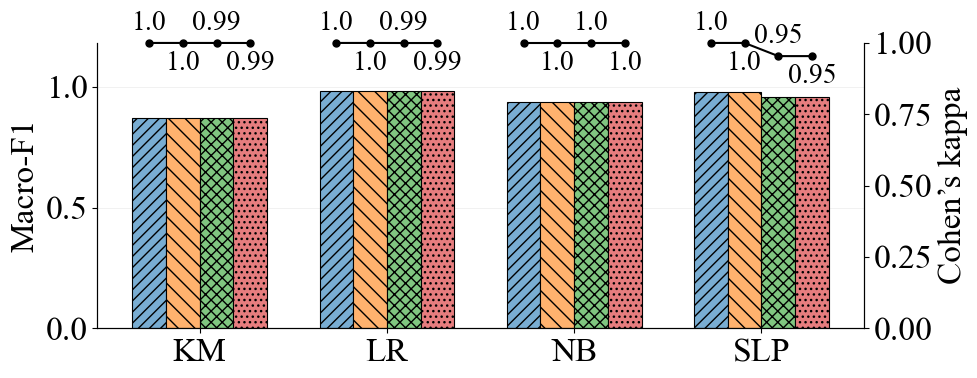

In [7]:
# Plot figure 12(a)
plot_approx_error("cicids17")

# Figure 12(b)

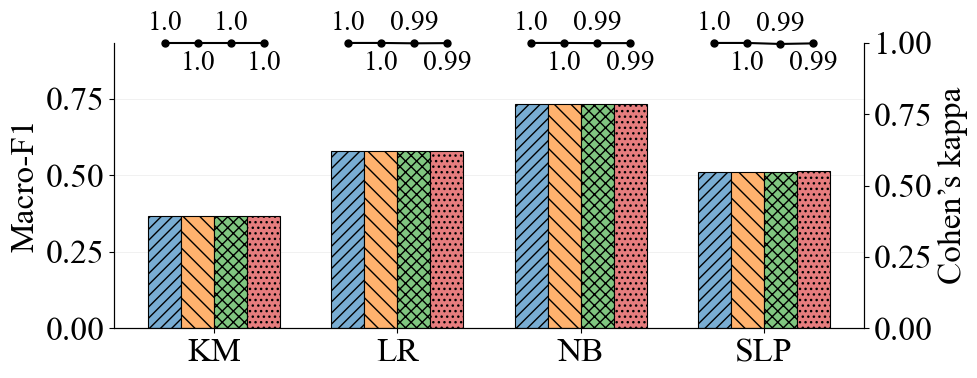

In [8]:
# Plot figure 12(b)
plot_approx_error("ciciot22")